# Mise en place du monitoring et analyse du data drift

L'objectif est de suivre en production le modèle de scoring déployé : erreurs, temps de réponse, distribution des scores et **dérive des données** par rapport au jeu d'entraînement.

Ce notebook analyse le **journal des appels** de l'API, actuellement alimenté par une **simulation de trafic** en deux phases de 1 000 appels :

- une **phase stable** : clients tirés au hasard dans le jeu de test
- une **phase de dérive** : clients plus jeunes ou à `EXT_SOURCE_2` plus faible surreprésentés

Environ 5 % des requêtes sont volontairement invalides. La **référence** est un échantillon de 10 000 clients du jeu d'entraînement, scorés par le même modèle.

Ce notebook permet d'évaluer les analyses pertinentes qui seront intégrées dans le dashboard de monitoring *Streamlit*.

**Prérequis :**

- `uv sync --group monitoring`
- fichier **.env** avec `DATABASE_URL`.

## 0. Initialisation

#### Import des modules

In [76]:
# General
import json  # noqa: I001

# Traitement des donnees
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Fonctions dédiées au monitoring, mutualisé avec le dashboard
from monitoring import analyse

#### Charte graphique

In [ ]:
# Couleurs principales
PURPLE = "#AB8EE4"
PURPLE_LIGHT = "#C9BCE3"
GOLD_DARK = "#FFE186"
GRIS = "#929292"

# Couleur et libelle de chaque groupe de clients
COULEURS = {"reference": GRIS, "stable": PURPLE, "derive": GOLD_DARK}
LIBELLES = {"reference": "Référence (entraînement)", "stable": "Phase stable", "derive": "Phase de dérive"}

def epurer(ax):
    """Mise en forme commune : cadre ferme sur les quatre cotes, sans grille."""
    ax.grid(False)

## 1. Chargement des données

#### Référence d'entraînement

Échantillon de 10 000 clients du jeu d'entraînement, avec le score du modèle en production.

In [78]:
# --- LECTURE DE LA REFERENCE ----------------------------------

# Récupération de l'échantillon du jeu d'entrainement avec le score du meme modele
reference = pd.read_parquet(analyse.FICHIER_REFERENCE)

# Seuil metier exporté avec le modele
SEUIL = json.loads((analyse.RACINE / "model" / "metadonnees.json").read_text(encoding="utf-8"))["seuil"]

# --- CONTROLE ----------------------------------

print(f"Réference   : {reference.shape[0]:,} clients x {reference.shape[1] - 1} variables")
print(f"Seuil de decision : {SEUIL}")
print(f"Score moyen : {reference['score'].mean():.4f}")

Réference   : 10,000 clients x 527 variables
Seuil de decision : 0.09
Score moyen : 0.0816


#### Journal des appels (simulation)

Le journal est lu dans la base désignée par `DATABASE_URL` (Supabase). Chaque appel est rattaché à sa phase à partir des horaires et des effectifs notés par le script de simulation.

In [79]:
# --- LECTURE DU JOURNAL ----------------------------------

# Connexion a la base, collecte du journal et identification des phases de la simulation
analyse.charger_env()
Tab = analyse.ajouter_phase(analyse.charger_journal(), analyse.charger_phases())

# Phases analysees
PHASES = ["stable", "derive"]

# --- CONTROLE ----------------------------------

print(f"Appels journalises     : {len(Tab)}")
print(f"Periode (UTC)          : {Tab['horodatage'].min():%d/%m/%Y %H:%M} -> {Tab['horodatage'].max():%H:%M}")
print(f"Appels hors simulation : {(Tab['phase'] == 'hors simulation').sum()}\n")
print("Répartition des appels valides / invalides :")
print(pd.crosstab(Tab["phase"], Tab["statut_http"]))

Appels journalises     : 2000
Periode (UTC)          : 29/09/2026 13:45 -> 13:57
Appels hors simulation : 0

Répartition des appels valides / invalides :
statut_http  200  422
phase                
derive       954   46
stable       948   52


## 2. Suivi opérationnel (erreurs, temps de réponse, scores)

#### Erreurs

L'API refuse les requêtes qu'elle ne peut pas scorer (erreur 422) et journalise la cause. Des erreurs sont injectées volontairement (~5 %) dans la simulation, l'objectif est de vérifier qu'elles sont bien tracées et que la dérive n'en provoque pas de nouvelles.

phase           stable  derive
cause                         
hors_plage          16      17
inconnues           10       9
manquantes          14      13
type incorrect      12       7 

Taux d'erreur : stable 5.2% | derive 4.6%


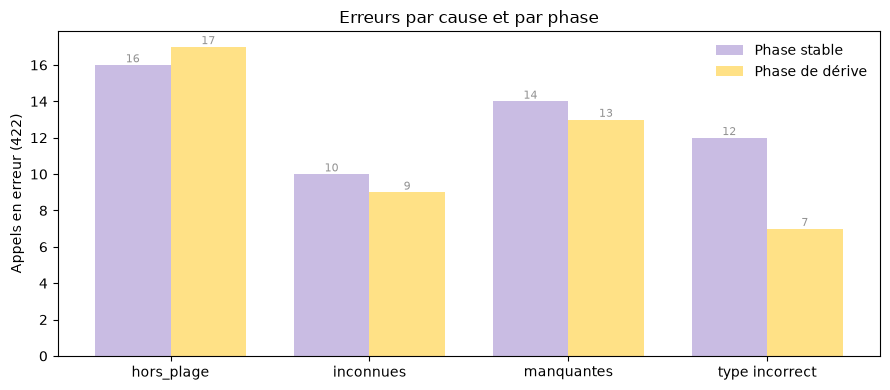

In [80]:
# --- CAUSES DES ERREURS ----------------------------------

def cause_erreur(erreur):
    """Cause d'une erreur du journal : categories de l'API (422 metier), type incorrect (422 Pydantic) ou autre."""
    if isinstance(erreur, dict):
        return " + ".join(sorted(erreur))
    return "type incorrect" if isinstance(erreur, list) else "autre"

# Récupération des erreurs
Simulation = Tab[Tab["phase"].isin(PHASES)]
Erreurs = Simulation[Simulation["statut_http"] != 200].copy()
Erreurs["cause"] = Erreurs["erreur"].map(cause_erreur)

# Effectifs par cause et taux d'erreur par phase
par_cause = Erreurs.groupby(["cause", "phase"]).size().unstack(fill_value=0)[PHASES]
taux = Erreurs.groupby("phase").size() / Simulation.groupby("phase").size()

# --- CONTROLE ----------------------------------

print(par_cause, "\n")
print("Taux d'erreur : " + " | ".join(f"{phase} {taux[phase]:.1%}" for phase in PHASES))

# --- FIGURE ----------------------------------

fig, ax = plt.subplots(figsize=(9, 4))

# Barres groupees : une grappe par cause, une barre par phase
pos = np.arange(len(par_cause))
largeur = 0.38
for decalage, phase in zip((-largeur / 2, largeur / 2), PHASES):
    barres = ax.bar(pos + decalage, par_cause[phase], largeur, label=LIBELLES[phase], color=COULEURS[phase])
    ax.bar_label(barres, fontsize=8, color=GRIS)

# Mise en forme
ax.set_xticks(pos, par_cause.index)
ax.set_ylabel("Appels en erreur (422)")
ax.set_title("Erreurs par cause et par phase")
ax.legend(frameon=False)
epurer(ax)
plt.tight_layout()
plt.show()

Observations :

- **Aucune panne serveur** : tous les appels de la simulation répondent 200 ou 422, aucune erreur 500.
- **Taux d'erreur**, conforme à la cible de 5 % d'invalides injectés.

#### Temps de réponse

La **latence** est le temps de traitement de l'API (validation, modèle et réponse). Le **temps d'inférence** est celui du modèle seul : la différence donne le coût du reste du traitement.

Latence de l'API (ms)
           50%    95%     max
phase                       
stable  145.0  214.0  1817.0
derive  116.0  211.0  1418.0 

Temps d'inference du modele (ms)
           50%    95%     max
phase                       
stable  107.0  196.0  1632.0
derive  100.0  195.0  1318.0 

Part du modele dans la latence (mediane) : 89%


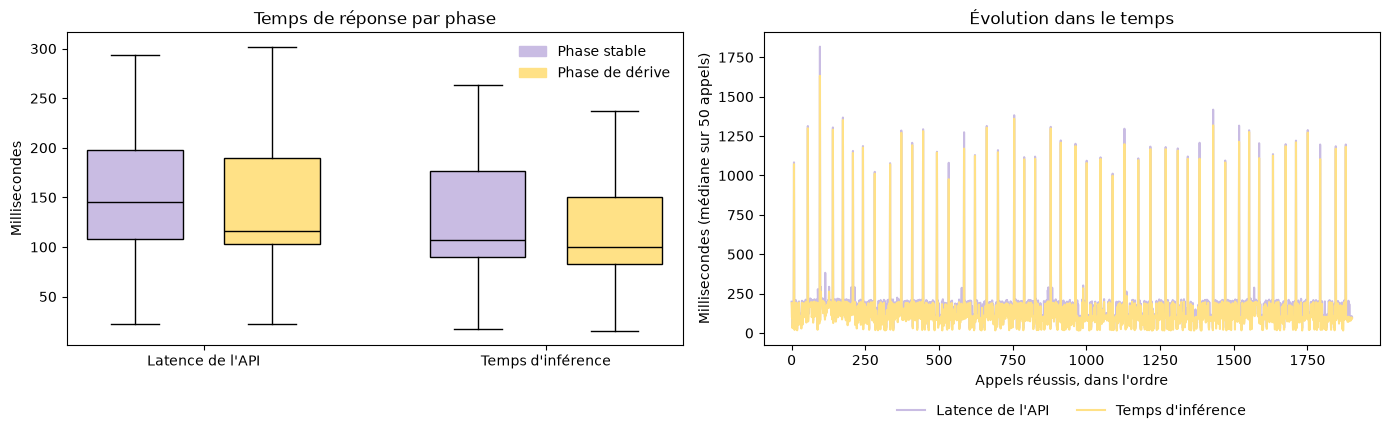

In [81]:
# --- TEMPS DE REPONSE ----------------------------------

# Appels reussis uniquement
Reussis = Simulation[Simulation["statut_http"] == 200]

def resume(colonne):
    """Mediane, 95e centile et maximum d'une duree, par phase."""
    return Reussis.groupby("phase")[colonne].describe(percentiles=[.5, .95]).loc[PHASES, ["50%", "95%", "max"]].round(0)

# --- CONTROLE ----------------------------------

print("Latence de l'API (ms)\n", resume("latence_ms"), "\n")
print("Temps d'inference du modele (ms)\n", resume("temps_inference_ms"), "\n")
print(f"Part du modele dans la latence (mediane) : {(Reussis['temps_inference_ms'] / Reussis['latence_ms']).median():.0%}")

# --- FIGURE ----------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Boites : latence puis temps d'inference, une boite par phase (valeurs extremes hors du cadre)
ax = axes[0]
donnees = [Reussis.loc[Reussis["phase"] == phase, colonne] for colonne in ("latence_ms", "temps_inference_ms") for phase in PHASES]
boites = ax.boxplot(donnees, positions=[1, 2, 3.5, 4.5], widths=0.7, showfliers=False, patch_artist=True, medianprops={"color": "black"})
for boite, phase in zip(boites["boxes"], PHASES * 2):
    boite.set_facecolor(COULEURS[phase])
ax.set_xticks([1.5, 4], ["Latence de l'API", "Temps d'inférence"])
ax.set_ylabel("Millisecondes")
ax.set_title("Temps de réponse par phase")
ax.legend(handles=[Patch(color=COULEURS[phase], label=LIBELLES[phase]) for phase in PHASES], frameon=False)
epurer(ax)

# Evolution du temps de réponse
ax = axes[1]
ordre = Reussis.reset_index(drop=True)
for colonne, couleur, libelle in (("latence_ms", PURPLE, "Latence de l'API"), ("temps_inference_ms", GOLD_DARK, "Temps d'inférence")):
    ax.plot(ordre[colonne], color=couleur, label=libelle)

# Mise en forme
ax.set_xlabel("Appels réussis, dans l'ordre")
ax.set_ylabel("Millisecondes (médiane sur 50 appels)")
ax.set_title("Évolution dans le temps")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
epurer(ax)

plt.tight_layout()
plt.show()

Observations :

- **La latence médiane est de 145 ms en phase stable et de 116 ms en phase de dérive**, avec un 95e centile stable à 211-214 ms : la dérive ne dégrade pas le temps de réponse.
- **Le modèle représente environ 90 % de la latence** : le temps d'inférence médian est d'environ 100 ms contre 116-145 ms de latence totale. C'est le **premier goulot d'étranglement**.
- **Le serveur est environ quatre fois plus lent que le poste de développement** : une prédiction y prend environ 100 ms, contre 22 à 27 ms mesurées en local. L'offre gratuite de Render partage un processeur limité.
- **Quelques appels sont dix fois plus lents que les autres** : on observe des pics autour de 1,3 s, allant jusqu'à 1,8 s, à attribuer à la réparition de charge du service Render qui mutualise les ressources.


#### Distribution des scores

Les scores de production sont comparés à ceux de la référence.

           Clients  Score moyen  Score median  Taux de refus
reference    10000        0.082         0.048          0.285
stable         948        0.078         0.050          0.284
derive         954        0.098         0.064          0.369


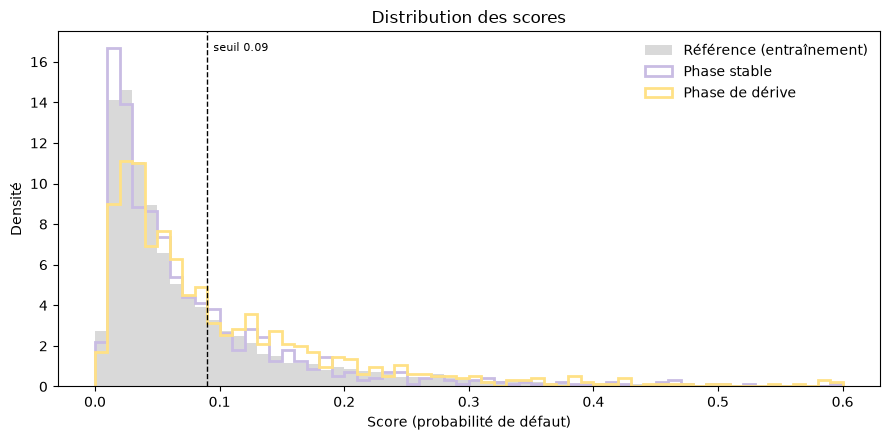

In [82]:
# --- SCORES PAR GROUPE ----------------------------------

# Score de la reference et des simulations
Scores = {"reference": reference["score"]} | {phase: Reussis.loc[Reussis["phase"] == phase, "score"] for phase in PHASES}

# Synthese
synthese = pd.DataFrame({
    "Clients": {groupe: len(score) for groupe, score in Scores.items()},
    "Score moyen": {groupe: score.mean() for groupe, score in Scores.items()},
    "Score median": {groupe: score.median() for groupe, score in Scores.items()},
    "Taux de refus": {groupe: (score >= SEUIL).mean() for groupe, score in Scores.items()},
})

print(synthese.round(3))

# --- FIGURE ----------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))

# Histogrammes en densite, scores ecretes a 0,6 pour la lisibilite
classes = np.linspace(0, 0.6, 61)
for groupe, score in Scores.items():
    if groupe == "reference":
        ax.hist(score.clip(upper=0.6), bins=classes, density=True, color=COULEURS[groupe], alpha=0.35, label=LIBELLES[groupe])
    else:
        ax.hist(score.clip(upper=0.6), bins=classes, density=True, histtype="step", lw=2, color=COULEURS[groupe], label=LIBELLES[groupe])

# Seuil de decision
ax.axvline(SEUIL, color="black", ls="--", lw=1)
ax.text(SEUIL + 0.005, ax.get_ylim()[1] * 0.97, f"seuil {SEUIL}", fontsize=8, va="top")

ax.set_xlabel("Score (probabilité de défaut)")
ax.set_ylabel("Densité")
ax.set_title("Distribution des scores")
ax.legend(frameon=False)
epurer(ax)
plt.tight_layout()
plt.show()

Observations :

- **La phase stable est représentative de la référence** : score moyen de 0,078 contre 0,082, taux de refus de 28,4 % contre 28,5 %.
- **La phase de dérive décale les scores** : comme attendu, on observe un score moyen de 0,098 et un **taux de refus de 36,9 %, soit 8,4 points de plus**. 
- **La distribution des scores est donc un indicateur de dérive utilisable sans connaître les défauts réels**, contrairement à la performance du modèle, qu'on ne peut mesurer qu'une fois les remboursements connus.
- **Un score plus élevé ne prouve pas que les clients feront plus défaut** : il montre que la population a changé et que le modèle la juge plus risquée. Savoir si ce jugement est correct exige les défauts réels.

## 3. Dérive des données

Le **data drift** est un changement de la distribution des variables d'entrée entre la référence (l'entraînement) et la production. Si la population change, les prédictions du modèle, ou le seuil de décision fixé peuvent devenir moins fiables sans qu'aucune erreur ne remonte.

#### Variables surveillées et méthode

- Variables : les **20 plus importantes pour le modèle** (gain de LightGBM) et le score : une dérive sur une variable sans influence ne change pas les décisions.
- Méthode : le **PSI** (*Population Stability Index*), standard du scoring de crédit. L'étendue de la variable est découpée en tranches de même largeur, puis on compare la part de clients de chaque tranche entre la référence et la production. La convention est de lire un PSI **sous 0,1 comme stable**, **entre 0,1 et 0,25 comme un changement modéré** et **au-dessus de 0,25 comme un changement important**. 
- Verdict global : Evidently déclare le jeu de données en dérive lorsque **50 % des colonnes** dérivent.

In [83]:
# --- VARIABLES SURVEILLEES ----------------------------------

# Part de l'importance (gain) de chaque variable dans le modele en production
Importances = analyse.importance_variables()

# Les plus importantes, surveillees avec le score
N_VARIABLES = 20
VARIABLES = list(Importances.head(N_VARIABLES).index)

# --- CONTROLE ----------------------------------

print(f"Les {N_VARIABLES} premieres variables portent {Importances.head(N_VARIABLES).sum():.0%} de l'importance du modele\n")
print(Importances.head(N_VARIABLES).round(3).to_string())

Les 20 premieres variables portent 57% de l'importance du modele

EXT_SOURCE_2                              0.145
EXT_SOURCE_3                              0.142
EXT_SOURCE_1                              0.049
CREDIT_TERM                               0.032
DAYS_EMPLOYED                             0.027
DAYS_BIRTH                                0.018
INS_DPD_MEAN                              0.016
BURO_DAYS_CREDIT_MEAN                     0.015
PREV_DAYS_LAST_DUE_1ST_VERSION_MAX        0.013
BURO_DAYS_CREDIT_MAX                      0.013
PREV_NAME_CONTRACT_STATUS_Refused_PART    0.012
INS_PAYMENT_PERC_MEAN                     0.012
NAME_EDUCATION_TYPE_Higher_education      0.011
AMT_ANNUITY                               0.011
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN          0.011
AMT_GOODS_PRICE                           0.010
DAYS_EMPLOYED_PERCENT                     0.009
OWN_CAR_AGE                               0.009
PREV_AMT_DOWN_PAYMENT_MAX                 0.008
CODE_GENDER_M         

#### Rapports de dérive

Un rapport Evidently par phase compare les appels réussis de la phase à la référence : le PSI est calculé pour chacune des 20 variables et pour le score.

Phase stable    : 948 appels | 0 colonnes en derive sur 21 (0%) | derive globale : non
Phase de dérive : 954 appels | 3 colonnes en derive sur 21 (14%) | derive globale : non


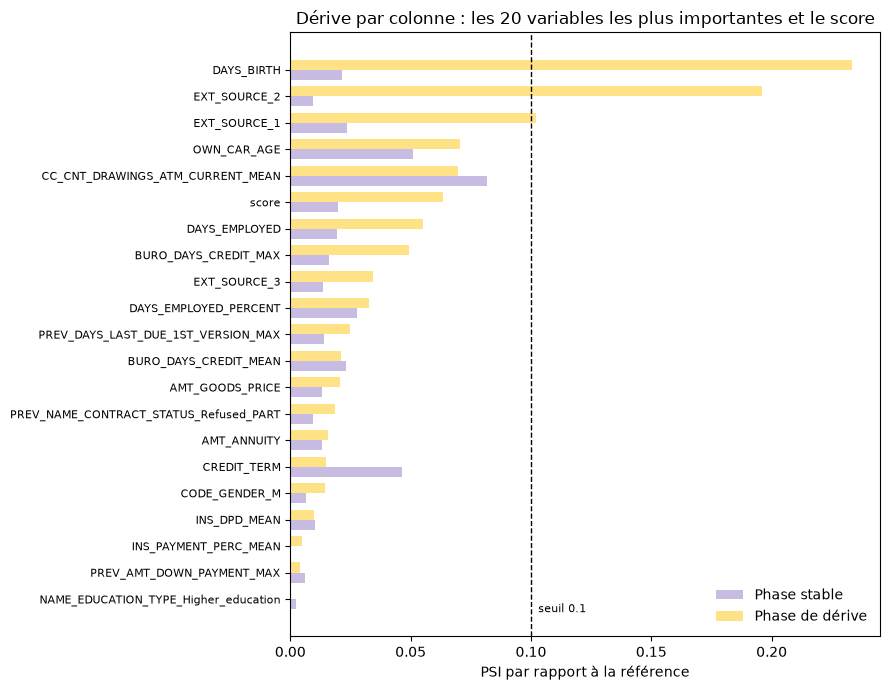

In [84]:
# --- RAPPORTS DE DERIVE ----------------------------------

# Variables et score des appels reussis, par phase
Entrees = analyse.entrees_a_plat(Tab)
Actuel = {phase: Entrees.loc[Reussis.index[Reussis["phase"] == phase]] for phase in PHASES}

# Un rapport Evidently par phase, compare a la reference (test PSI, seuil 0,1)
Rapports = {phase: analyse.rapport_drift(Actuel[phase], reference, VARIABLES) for phase in PHASES}

# PSI de chaque colonne (variables et score), par phase
Psi = pd.DataFrame({phase: analyse.psi_par_colonne(Rapports[phase]) for phase in PHASES})

# --- CONTROLE ----------------------------------

for phase in PHASES:
    verdict = analyse.verdict_global(Rapports[phase])
    print(f"{LIBELLES[phase]:16s}: {len(Actuel[phase])} appels | {verdict['en_derive']} colonnes en derive sur {len(Psi)} "
          f"({verdict['part']:.0%}) | derive globale : {'oui' if verdict['derive_globale'] else 'non'}")

# --- FIGURE ----------------------------------

# Colonnes triees par PSI croissant en phase de derive : la plus forte en haut
tri = Psi.sort_values("derive")

fig, ax = plt.subplots(figsize=(9, 7))
pos = np.arange(len(tri))
hauteur = 0.38
for decalage, phase in zip((-hauteur / 2, hauteur / 2), PHASES):
    ax.barh(pos + decalage, tri[phase], hauteur, label=LIBELLES[phase], color=COULEURS[phase])

# Seuil de derive
ax.axvline(analyse.SEUIL_PSI, color="black", ls="--", lw=1)
ax.text(analyse.SEUIL_PSI + 0.003, -0.6, f"seuil {analyse.SEUIL_PSI}", fontsize=8, va="bottom")

# Mise en forme
ax.set_yticks(pos, tri.index, fontsize=8)
ax.set_xlabel("PSI par rapport à la référence")
ax.set_title("Dérive par colonne : les 20 variables les plus importantes et le score")
ax.legend(frameon=False, loc="lower right")
epurer(ax)
plt.tight_layout()
plt.show()

Observations :

- **En phase stable, aucune colonne ne dérive** : le PSI le plus élevé est de 0,08, sous le seuil de 0,1. Sur des phases d'environ 950 appels, un trafic représentatif de l'entraînement ne déclenche pas de fausse alerte sur ces 21 colonnes.
- **En phase de dérive, trois colonnes dépassent le seuil** : `DAYS_BIRTH` (PSI de 0,233), `EXT_SOURCE_2` (0,196) et `EXT_SOURCE_1` (0,102). Les deux premières sont celles que la simulation a déplacées : le PSI les retrouve en tête.
- **`EXT_SOURCE_1` dérive par association.** La simulation ne la touche pas, mais elle est fortement corrélée à l'âge : surreprésenter les jeunes la déplace aussi.
- **Le score reste sous le seuil alors que le taux de refus monte de 8,4 points.** Le PSI mesure l'écart sur toute la distribution, or la décision ne dépend que de la part des scores au-dessus de 0,09, cette métrique n'est donc pas suffisante.
- **Le verdict global d'Evidently est « pas de dérive »** dans les deux phases : 3 colonnes sur 21 (14 %) sont loin du seuil de 50 % par défaut.

#### Variables en dérive

Les distributions des colonnes dont le PSI dépasse le seuil en phase de dérive, comparées à la référence et à la phase stable. L'âge remplace `DAYS_BIRTH` pour la lisibilité.

              reference  stable  derive
DAYS_BIRTH        43.92   44.55   40.09
EXT_SOURCE_2       0.52    0.51    0.44
EXT_SOURCE_1       0.50    0.51    0.44


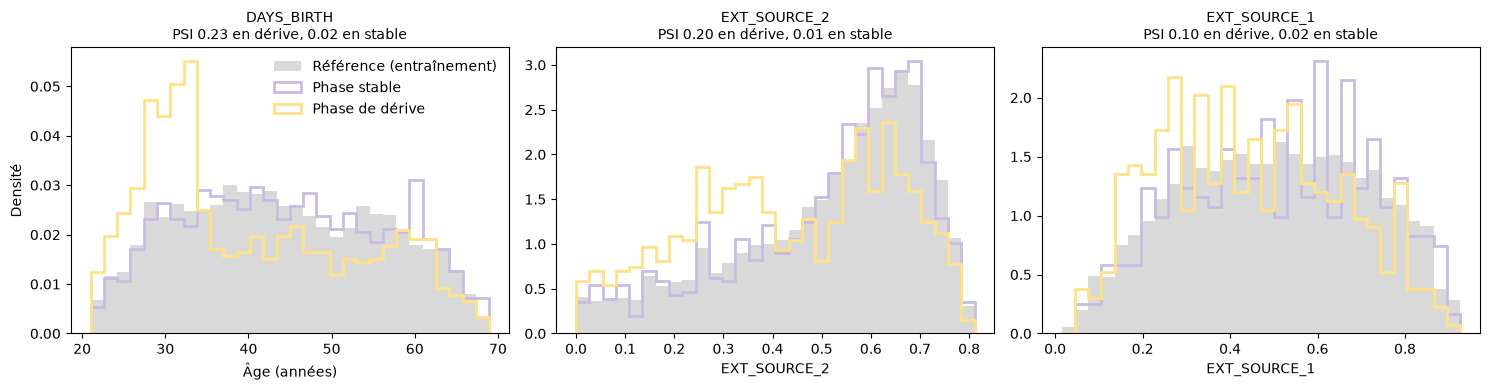

In [85]:
# --- VARIABLES EN DERIVE ----------------------------------

# Colonnes au-dessus du seuil en phase de derive
en_derive = Psi.loc[Psi["derive"] >= analyse.SEUIL_PSI, "derive"].sort_values(ascending=False).index

def valeurs(donnees, colonne):
    """Valeurs d'une colonne, l'age en annees remplacant DAYS_BIRTH (jours avant la demande, negatifs)."""
    serie = donnees[colonne].dropna()
    return -serie / 365.25 if colonne == "DAYS_BIRTH" else serie

# Groupes compares
GROUPES = {"reference": reference, "stable": Actuel["stable"], "derive": Actuel["derive"]}

# --- CONTROLE ----------------------------------

print(pd.DataFrame({groupe: {colonne: valeurs(donnees, colonne).mean() for colonne in en_derive}
                    for groupe, donnees in GROUPES.items()}).round(2))

# --- FIGURE ----------------------------------

fig, axes = plt.subplots(1, len(en_derive), figsize=(5 * len(en_derive), 4))
axes = np.atleast_1d(axes)
for ax, colonne in zip(axes, en_derive):
    # Classes communes aux trois groupes, definies sur la reference
    classes = np.histogram_bin_edges(valeurs(reference, colonne), bins=30)
    for groupe, donnees in GROUPES.items():
        if groupe == "reference":
            style = {"color": COULEURS[groupe], "alpha": 0.35}
        else:
            style = {"histtype": "step", "lw": 2, "color": COULEURS[groupe]}
        ax.hist(valeurs(donnees, colonne), bins=classes, density=True, label=LIBELLES[groupe], **style)
    ax.set_xlabel("Âge (années)" if colonne == "DAYS_BIRTH" else colonne)
    ax.set_title(f"{colonne}\nPSI {Psi.loc[colonne, 'derive']:.2f} en dérive, {Psi.loc[colonne, 'stable']:.2f} en stable", fontsize=10)
    epurer(ax)

axes[0].set_ylabel("Densité")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

Observations :

- **La population de la phase de dérive est plus jeune, avec un score externe plus faible** : âge moyen de 40,1 ans contre 43,9 ans pour la référence, `EXT_SOURCE_2` de 0,44 contre 0,52. La phase stable reste au niveau de la référence (44,6 ans et 0,51).
- **La moyenne ne bouge que de 3,8 ans pour l'âge.** Le PSI, qui compare toute la distribution, le repère nettement (0,23) : l'histogramme montre un excès de clients de moins de 35 ans, que la moyenne dilue.
- **`EXT_SOURCE_1` baisse aussi** (0,44 contre 0,50) sans avoir été visée : c'est l'effet de la corrélation relevé plus haut.

#### Export des rapports Evidently

Les rapports complets (distributions, tests, tableau par colonne) sont exportés en HTML dans le dossier `livrables/`.

In [86]:
# --- EXPORT DES RAPPORTS ----------------------------------

# Rapports Evidently complets (HTML, environ 5 Mo chacun) dans le dossier des livrables, ignore par git
for phase in PHASES:
    Rapports[phase].save_html(str(analyse.RACINE / "livrables" / f"Jacquinot_Lenny_6_rapport_drift_{phase}_102026.html"))

## 4. Fenêtre d'observation

En production, on ne compare pas tous les appels depuis le lancement à la référence : le stock cumulé diluerait une dérive récente. On compare une **fenêtre récente**, les N derniers appels, à une **référence fixe**, ici l'échantillon d'entraînement. Reste à choisir N car si trop petite, la fenêtre est bruyante et déclenche de fausses alertes, si trop grande, elle détecte tard.

On réalise ici une étude de sensibilié à la largeur de fenêtre. Pour cela on a recodé le calcul du PSI, qui produit un résultat plus rapide qu'Evidently qui regénère un rapport.

#### Vérification du calcul rapide

In [87]:
# --- VERIFICATION DU CALCUL RAPIDE ----------------------------------

# Colonnes surveillees : les 20 variables et le score
COLONNES = VARIABLES + ["score"]

# Le PSI rapide doit reproduire celui des rapports Evidently
for phase in PHASES:
    ecart = (analyse.psi_colonnes(Actuel[phase], reference, COLONNES) - Psi[phase]).abs().max()
    print(f"{LIBELLES[phase]:16s}: ecart maximal avec Evidently {ecart:.1e}")

Phase stable    : ecart maximal avec Evidently 0.0e+00
Phase de dérive : ecart maximal avec Evidently 0.0e+00


#### Instant de détection de la dérive avec PSI glissant

Des fenêtres de 500 appels, avancées de 50 en 50, sont comparées à la référence. La courbe montre à quel moment la dérive devient visible.

DAYS_BIRTH  : seuil atteint par la fenetre finissant a l'appel 1350, 402 appels apres le debut de la derive (80% de la fenetre)
EXT_SOURCE_2: seuil atteint par la fenetre finissant a l'appel 1300, 352 appels apres le debut de la derive (70% de la fenetre)


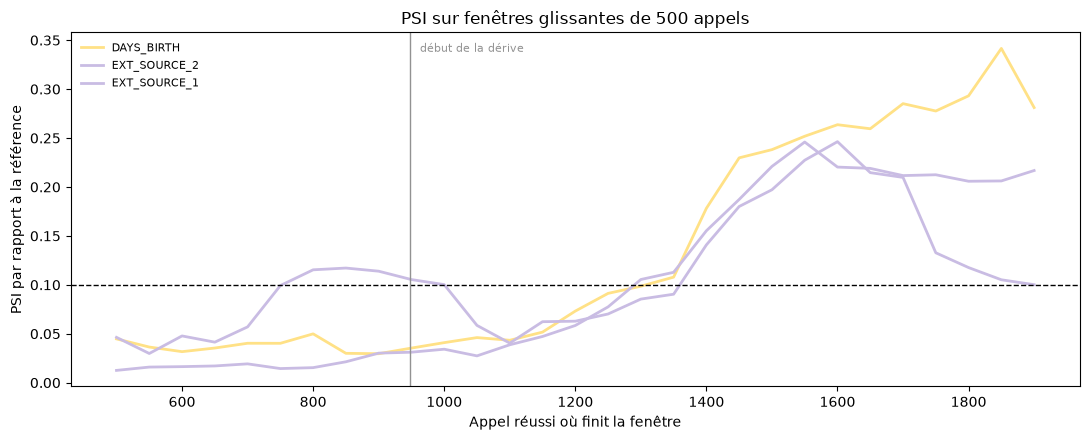

In [88]:
# --- PSI GLISSANT ----------------------------------

# Appels reussis de la simulation, dans l'ordre, avec les variables et le score
Ordre = Entrees.loc[Reussis.index]

# Fenetres de 500 appels avancees de 50 en 50, comparees a la reference
TAILLE, PAS = 500, 50
fins = range(TAILLE, len(Ordre) + 1, PAS)
Glissant = pd.DataFrame({fin: analyse.psi_colonnes(Ordre.iloc[fin - TAILLE:fin], reference, COLONNES) for fin in fins}).T

# Appel a partir duquel les clients de la phase de derive arrivent
DEBUT_DERIVE = int((Reussis["phase"] == "stable").sum())

# --- CONTROLE ----------------------------------

# Premiere fenetre au-dessus du seuil pour les colonnes deplacees, et part de la fenetre deja en derive
for colonne in ("DAYS_BIRTH", "EXT_SOURCE_2"):
    fin = Glissant.index[Glissant[colonne] >= analyse.SEUIL_PSI].min()
    print(f"{colonne:12s}: seuil atteint par la fenetre finissant a l'appel {fin}, {fin - DEBUT_DERIVE} appels apres le debut de la derive "
          f"({(fin - DEBUT_DERIVE) / TAILLE:.0%} de la fenetre)")

# --- FIGURE ----------------------------------

fig, ax = plt.subplots(figsize=(11, 4.5))

# Colonnes identifiees
STYLES = {
    "DAYS_BIRTH": {"color": GOLD_DARK},
    "EXT_SOURCE_2": {"color": PURPLE},
    "EXT_SOURCE_1": {"color": PURPLE_LIGHT},
}
for colonne, style in STYLES.items():
    ax.plot(Glissant.index, Glissant[colonne], lw=2, label=colonne, **style)

# Seuil de derive et debut de la phase de derive
ax.axhline(analyse.SEUIL_PSI, color="black", ls="--", lw=1)
ax.axvline(DEBUT_DERIVE, color=GRIS, lw=1)
ax.text(DEBUT_DERIVE + 15, ax.get_ylim()[1] * 0.97, "début de la dérive", color=GRIS, fontsize=8, va="top")

ax.set_xlabel("Appel réussi où finit la fenêtre")
ax.set_ylabel("PSI par rapport à la référence")
ax.set_title(f"PSI sur fenêtres glissantes de {TAILLE} appels")
ax.legend(frameon=False, loc="upper left", fontsize=8)
epurer(ax)
plt.tight_layout()
plt.show()

Observations :

- **La dérive devient visible après 350 à 400 appels.** `EXT_SOURCE_2` franchit le seuil pour la fenêtre qui finit à l'appel 1 300, et `DAYS_BIRTH` à l'appel 1 350. Les fenêtres contiennent alors 70 % à 80 % de clients de la phase de dérive : le PSI monte à mesure que la fenêtre se renouvelle.

#### Bruit du PSI selon la taille de la fenêtre

Pour savoir à partir de quelle taille le seuil de 0,1 est fiable, il faut mesurer le PSI **quand il n'y a aucune dérive**. Pour cette étude les appels de la simulation ne suffisent pas, on utilise donc l'échantillon d'entraînement, coupé en deux moitiés indépendantes : l'une sert de référence, l'autre de réservoir de fenêtres. Toute alerte est considéré comme une fausse alerte.

Colonnes tres manquantes : EXT_SOURCE_1 (55%), CC_CNT_DRAWINGS_ATM_CURRENT_MEAN (80%), OWN_CAR_AGE (66%)

      Fausse alerte (21 colonnes)  PSI max median  PSI max 95e centile
100                          1.00           0.529                0.929
250                          1.00           0.167                0.254
500                          0.40           0.091                0.150
1000                         0.02           0.045                0.078
2000                         0.00           0.024                0.038 

                                  Fausse alerte (500 appels)  Fausse alerte (1000 appels)  Valeurs renseignees
OWN_CAR_AGE                                             0.24                         0.02                 0.34
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN                        0.14                         0.00                 0.20
EXT_SOURCE_1                                            0.10                         0.00                 0.45
DAYS_EMPLOYED         

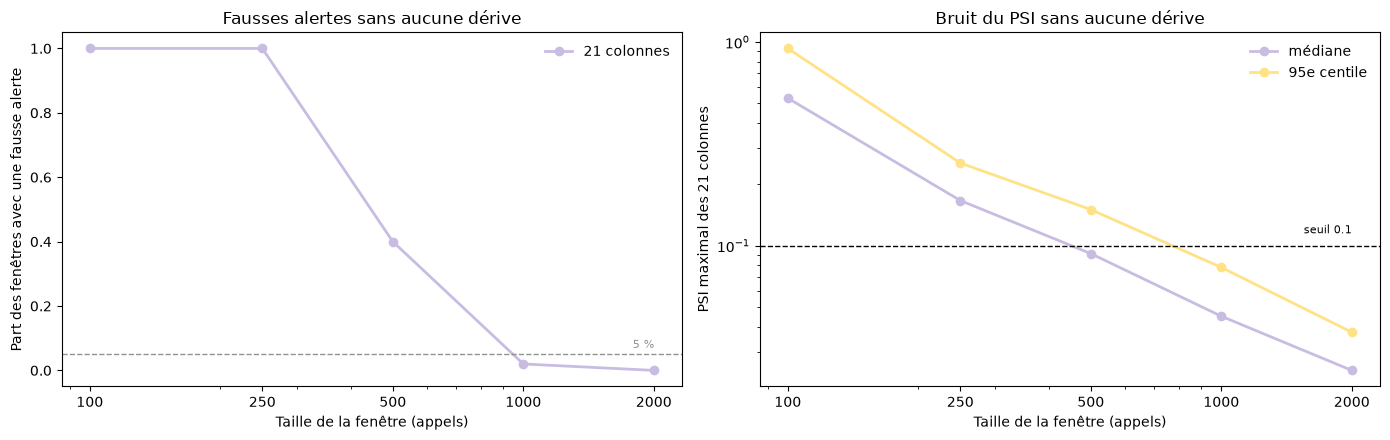

In [89]:
# --- BRUIT DU PSI SELON LA TAILLE DE FENETRE ----------------------------------

# Deux moities independantes de l'echantillon d'entrainement
hasard = np.random.default_rng(42)
melange = hasard.permutation(len(reference))
ref_a, reservoir = reference.iloc[melange[:5000]], reference.iloc[melange[5000:]]

# Colonnes tres manquantes (plus de 50 % de valeurs absentes)
manquantes = reference[COLONNES].isna().mean()
creuses = [colonne for colonne in COLONNES if manquantes[colonne] > 0.5]

# 50 fenetres tirees au hasard pour chaque taille
TAILLES = [100, 250, 500, 1000, 2000]
N_FENETRES = 50
Bruit = {
    taille: pd.DataFrame([
        analyse.psi_colonnes(reservoir.iloc[hasard.choice(len(reservoir), taille, replace=False)], ref_a, COLONNES)
        for _ in range(N_FENETRES)
    ])
    for taille in TAILLES
}

# Synthese par taille : fausse alerte = au moins une colonne au-dessus du seuil
bruit = pd.DataFrame({
    "Fausse alerte (21 colonnes)": {t: (b.max(axis=1) >= analyse.SEUIL_PSI).mean() for t, b in Bruit.items()},
    "PSI max median": {t: b.max(axis=1).median() for t, b in Bruit.items()},
    "PSI max 95e centile": {t: b.max(axis=1).quantile(.95) for t, b in Bruit.items()},
})

# --- CONTROLE ----------------------------------

print(f"Colonnes tres manquantes : {', '.join(f'{c} ({manquantes[c]:.0%})' for c in creuses)}\n")
print(bruit.round(3).to_string(), "\n")

# Fausses alertes par colonne pour une fenetre de 500 appels, avec la part de valeurs renseignees
par_colonne = pd.DataFrame({
    "Fausse alerte (500 appels)": (Bruit[500] >= analyse.SEUIL_PSI).mean(),
    "Fausse alerte (1000 appels)": (Bruit[1000] >= analyse.SEUIL_PSI).mean(),
    "Valeurs renseignees": 1 - manquantes,
})
print(par_colonne.sort_values("Fausse alerte (500 appels)", ascending=False).head(5).round(2).to_string())

# --- FIGURE ----------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Taux de fausse alerte selon la taille de la fenetre
ax = axes[0]
ax.plot(bruit.index, bruit["Fausse alerte (21 colonnes)"], marker="o", color=PURPLE, lw=2, label="21 colonnes")
ax.axhline(0.05, color=GRIS, ls="--", lw=1)
ax.text(bruit.index[-1], 0.07, "5 %", color=GRIS, fontsize=8, ha="right")
ax.set_xscale("log")
ax.set_xticks(bruit.index, bruit.index)
ax.set_xlabel("Taille de la fenêtre (appels)")
ax.set_ylabel("Part des fenêtres avec une fausse alerte")
ax.set_title("Fausses alertes sans aucune dérive")
ax.legend(frameon=False)
epurer(ax)

# PSI maximal des 21 colonnes : mediane et 95e centile, avec le seuil
ax = axes[1]
ax.plot(bruit.index, bruit["PSI max median"], marker="o", color=PURPLE, lw=2, label="médiane")
ax.plot(bruit.index, bruit["PSI max 95e centile"], marker="o", color=GOLD_DARK, lw=2, label="95e centile")
ax.axhline(analyse.SEUIL_PSI, color="black", ls="--", lw=1)
ax.text(bruit.index[-1], analyse.SEUIL_PSI * 1.15, f"seuil {analyse.SEUIL_PSI}", fontsize=8, ha="right")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(bruit.index, bruit.index)
ax.set_xlabel("Taille de la fenêtre (appels)")
ax.set_ylabel("PSI maximal des 21 colonnes")
ax.set_title("Bruit du PSI sans aucune dérive")
ax.legend(frameon=False)
epurer(ax)

plt.tight_layout()
plt.show()

Observations :

- **Le bruit du PSI diminue à peu près comme l'inverse de la taille de la fenêtre.** Le seuil de 0,1 est **inférieur au bruit habituel** sous 500 appels.
- **Les fausses alertes sont systématiques sous 250 appels et disparaissent à 1 000.** Sur les 21 colonnes, elles touchent 100 % des fenêtres à 100 appels, seulement **2 % à 1 000** et 0 % à 2 000. Le 95e centile du PSI maximal passe sous le seuil à 1 000 appels (0,082).
- **Les colonnes denses s'en sortent mieux que les colonnes très manquantes :** `OWN_CAR_AGE` (24 %), `CC_CNT_DRAWINGS_ATM_CURRENT_MEAN` (14 %) et `EXT_SOURCE_1` (10 %) à 500 appels. À 1 000 appels, elles ne dépassent plus 2 %.
- **Une fenêtre de 1 000 appels semble donc le minimum fiable pour le seuil de 0,1**.

## 5. Synthèse

### Ce que le monitoring établit

- **Le service tient sous la simulation.** 2 000 appels, aucune panne serveur, et les 5 % d'erreurs injectées sont toutes tracées avec leur cause.
- **L'inférence' est le goulot d'étranglement.** Il pèse environ 90 % de la latence.
- **La dérive est détectée sans fausse alerte sur des phases d'environ 950 appels.** Aucune colonne sur 21 en phase stable (PSI maximal de 0,082), trois en phase de dérive : `DAYS_BIRTH` (0,233), `EXT_SOURCE_2` (0,196) et `EXT_SOURCE_1` (0,102).
- **La taille de la fenêtre décide de la fiabilité du signal.** Avec le seuil de 0,1, le bruit du PSI produit des fausses alertes sous 1 000 appels.

### Points de vigilance

- **Les variables très manquantes sont les plus fragiles,** elles concentrent les fausses alertes des petites fenêtres.
- **Le verdict global est trompeur pour une dérive concentrée.** Trois colonnes sur 21 (14 %) ne déclenchent pas le seuil global de 50 % : il faut évaluer colonne par colonne.
- **Le PSI du score ne suffit pas.** Il reste sous 0,1 alors que le taux de refus gagne 8,4 points : les deux se suivent ensemble.
- **La simulation est plus simple que la réalité.** La dérive est franche et brutale, sur deux variables, les dérives lentes, multivariées ou portant sur les valeurs manquantes ne sont pas testées.
- **Dérive et performance sont deux choses différentes.** Sans les défauts réels, connus bien plus tard, on détecte un changement de population, pas une dégradation du modèle.

### Recommandations d'exploitation

Les valeurs suivantes viennent des mesures de la section 4. Celles qui n'ont pas pu être mesurées sont présentées comme des propositions à calibrer.

- **Fenêtre** : les 1 000 derniers appels, comparés à la référence fixe d'entraînement.
- **Alerte à deux niveaux** : vigilance à partir d'un PSI de 0,1, niveau critique à partir de 0,25 (conventions usuelles), déclenchée seulement si l'écart persiste sur **deux fenêtres consécutives sans recouvrement**. On peut également suivre en parallèle le taux de refus (par exemple un écart de plus de 5 points avec la référence).
- **Fréquence** : au rythme de la fenêtre, c'est-à-dire tous les 1 000 appels, ou une fois par jour si le trafic est faible, avec un nombre minimal d'appels en dessous duquel on ne calcule rien. 
- **Historique** : purger les appels bruts à 90 jours, comme prévu, mais **conserver les PSI calculés**, qui ne contiennent aucune donnée personnelle : ils permettent de suivre la dérive à long terme.
- **Réentraînement** : à déclencher sur une dérive persistante des variables importantes **et** une performance mesurée en baisse une fois les défauts réels connus, pas sur le drift seul.